In [1]:
!pip install 'powerlaw'

In [2]:
import bmll2 as b2
from bmll2 import reference, Security, NormalisedSecurity, SparkHelper, get_market_data, get_market_data_range, VenueMarketError, get_market_tables, save_spark_dataframe, load_spark_dataframe

b2.get_file('modules/metaorder.py')
b2.get_file('modules/LMF.py')
b2.get_file('modules/calibration.py')

import metaorder as metaorder
import LMF as LMF
import calibration as calibration

import random
import math
import pandas as pd
import polars as pl
import numpy as np
from pandas import StringDtype
from datetime import timedelta

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import LogFormatterSciNotation

from statsmodels.sandbox.stats.runs import runstest_1samp
import powerlaw
import itertools
import pylab
import scipy.stats
import scipy.fft
from scipy.optimize import curve_fit
from sklearn.model_selection import ParameterGrid

from statsmodels.tsa.stattools import acf
from scipy.stats import t

from typing import Literal

# Synthetic metaorder configuration settings

## Fixed settings

The following settings define the market and trader participation assumptions used throughout the study and should not be modified.

- **trader_participation_distribution**: Distribution of trader participation rates. Fixed as `'power'`, corresponding to a power-law distribution.
- **exchange**: Exchange from which the data were obtained. Fixed as `'XJSE'`.

## User-configurable settings

The following settings control the construction of synthetic metaorders.

- **config**: Objective function used to select the optimal synthetic metaorder configuration.
    - `'metaorder'`: minimises \( e_M \)
    - `'LMF'`: minimises \( e_{LMF} \)
    - `'combined'`: minimises \( e_{combo} \)
- **grouped**: If `True`, the parameters \(N\) and \(\delta\) are constrained to be identical across all years. If `False`, they are estimated separately for each year.

In [42]:
trader_participation_distribution = 'power'
exchange                          = 'XJSE'
config                            = 'combined'
estimation_method                 = 'PSD'
grouped                           = False

In [44]:
%%time
files = b2.list_files(path = f'data/grid_search_9/{exchange}/{trader_participation_distribution}')

for f in files:
    b2.get_file(f'data/grid_search_9/{exchange}/{trader_participation_distribution}/{f}')

data = pl.scan_parquet(f'*{trader_participation_distribution}_grid_search.parquet').collect()

if trader_participation_distribution == 'homogenous':
    data.sort(['ticker', 'year', 'N'])
    data.head(10)
if trader_participation_distribution == 'power':
    data.sort(['ticker', 'year', 'N', 'delta'])
    data.head(10)

CPU times: user 2.97 s, sys: 144 ms, total: 3.12 s
Wall time: 20.6 s


In [45]:
b2.create_folder('figures_2', ensure_exists = True)
b2.create_folder('figures_2/time_independence', ensure_exists = True)
b2.create_folder(f'figures_2/time_independence/{exchange}', ensure_exists = True) 
b2.create_folder(f'figures_2/time_independence/{exchange}/calibrated', ensure_exists = True) 
b2.create_folder(f'figures_2/time_independence/{exchange}/calibrated/{config}', ensure_exists = True) 

# GRT

In [46]:
ticker   = 'GRT'

b2.get_file(f'data/trades/top_250/{ticker}_{exchange}.parquet')

def load_stock(parquet):
    try:
        df = pl.read_parquet(parquet)
        return df.sort(['DateTime', 'ExchangeSequenceNo'])
    except FileNotFoundError:
        return None

GRT = load_stock(f'{ticker}_{exchange}.parquet')

if (grouped == True):
    flag = 'grouped'
else:
    flag = 'ungrouped'
    
config_info = calibration.find_configs(data = data, grouped = grouped, trader_participation_distribution = 'power',
                           config = config, estimation_method = estimation_method,
                           lambda_penalty = 1, mix = [1, 1, 1]).filter(pl.col('ticker') == ticker)

if (grouped == True):
    list_cols = [
        col.name
            for col in config_info
                if col.dtype.base_type() == pl.List
    ]
    config_info = config_info.explode(list_cols)

config_info

ticker,year,N,$\delta$,$\alpha$,$\gamma$,\makecell{$\frac{Q}{V_D}$ \\ exponent},\makecell{$\phi$ \\ exponent},$\beta$,\makecell{$\mathrm{e}_{M}$ \\ (PSD)},\makecell{$\mathrm{e}_{LMF}$ \\ (PSD)},\makecell{$\mathrm{e}_{combo}$ \\ (PSD) (stnd)}
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GRT""",2023,50,3.0,1.531323,0.482646,0.363773,0.803306,0.191972,0.380553,0.032831,-2.063749
"""GRT""",2024,100,3.0,1.549268,0.433737,0.309595,0.650975,0.120187,0.422609,0.08058,-1.534835
"""GRT""",2025,500,2.0,1.521509,0.489648,0.32468,0.739892,0.143926,0.42741,0.021388,-2.075653


In [47]:
trader_participation_distribution = 'power'
group                             = 'year'
N                                 = config_info['N'].to_list()
delta                             = config_info[f'$\\delta$'].to_list() 

In [48]:
if ticker == 'GRT':
    col = 'olive'
elif ticker == 'GFI':
    col = 'purple'
else:
    col = 'blue'

In [49]:
%%time
GRT_metaorders = metaorder.metaorder_data(GRT, group = group, N = N, trader_participation_distribution = trader_participation_distribution, delta = delta)

CPU times: user 13.7 s, sys: 255 ms, total: 14 s
Wall time: 10.8 s


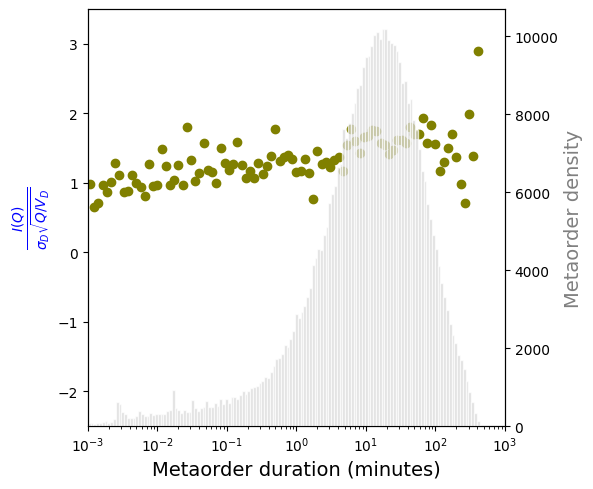

In [50]:
n_intervals = 100

df = GRT_metaorders.with_columns(pl.col('duration (min)').alias('x_meta'),
                            (pl.col('metaorder impact') / (pl.col('20 AD volatility') * np.sqrt((pl.col('volume traded') / pl.col('20 AD volume'))))).fill_nan(None).alias('y_meta'))

bins = np.logspace(-3, 3, n_intervals)
df   = df.with_columns([pl.Series('bin', np.digitize(df['x_meta'].to_numpy(), bins) - 1)])

all_bins = pl.DataFrame({'bin': np.arange(len(bins) - 1)})
binned   = df.group_by('bin').agg(pl.col('y_meta').mean().alias('y_mean')).sort('bin')
binned   = all_bins.join(binned, on = 'bin', how = 'left').sort('bin')

bin_centers = (bins[:-1] + bins[1:]) / 2
binned      = binned.with_columns(x_center = bin_centers)

fig, ax1 = plt.subplots(figsize = (6, 6))

ax1.set_xscale('log')
ax1.set_xlim(1e-3, 1e3)
ax1.set_ylim(-2.5, 3.5)

ax1.scatter(binned['x_center'], binned['y_mean'], color = col, marker = 'o')

ax1.set_xlabel('Metaorder duration (minutes)', fontsize = 14)
ax1.set_ylabel(r'$\frac{I(Q)}{\sigma_{D} \sqrt{Q/V_{D}}}$', fontsize = 14, color = 'blue')
ax1.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))

# Histogram (right axis)
ax2 = ax1.twinx()
bins = np.logspace(-3, 3, 150)
ax2.hist(df['x_meta'], bins = bins, color = 'lightgray', edgecolor = 'white', alpha = 0.7)
ax2.set_ylabel('Metaorder density', fontsize = 14, color = 'gray')

ax1.set_box_aspect(1)
plt.tight_layout()

plt.savefig(f'{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf', f'figures_2/time_independence/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/time_independence/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf')

plt.show()

# GFI

In [51]:
ticker   = 'GFI'

b2.get_file(f'data/trades/top_250/{ticker}_{exchange}.parquet')

def load_stock(parquet):
    try:
        df = pl.read_parquet(parquet)
        return df.sort(['DateTime', 'ExchangeSequenceNo'])
    except FileNotFoundError:
        return None

GFI = load_stock(f'{ticker}_{exchange}.parquet')

if (grouped == True):
    flag = 'grouped'
else:
    flag = 'ungrouped'
    
config_info = calibration.find_configs(data = data, grouped = grouped, trader_participation_distribution = 'power',
                           config = config, estimation_method = estimation_method,
                           lambda_penalty = 1, mix = [1, 1, 1]).filter(pl.col('ticker') == ticker)

if (grouped == True):
    list_cols = [
        col.name
            for col in config_info
                if col.dtype.base_type() == pl.List
    ]
    config_info = config_info.explode(list_cols)

config_info

ticker,year,N,$\delta$,$\alpha$,$\gamma$,\makecell{$\frac{Q}{V_D}$ \\ exponent},\makecell{$\phi$ \\ exponent},$\beta$,\makecell{$\mathrm{e}_{M}$ \\ (PSD)},\makecell{$\mathrm{e}_{LMF}$ \\ (PSD)},\makecell{$\mathrm{e}_{combo}$ \\ (PSD) (stnd)}
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GFI""",2023,30,4.0,1.577393,0.57226,0.384842,0.966068,0.167533,0.461083,0.003265,-1.375177
"""GFI""",2024,30,4.0,1.565015,0.561394,0.3586,0.969508,0.142882,0.525155,0.002319,-1.387418
"""GFI""",2025,50,4.0,1.645178,0.642794,0.299008,0.87718,0.152225,0.43697,0.001451,-1.398647


In [52]:
trader_participation_distribution = 'power'
N                                 = config_info['N'].to_list()
delta                             = config_info[f'$\\delta$'].to_list()
group                             = 'year'

In [53]:
if ticker == 'GRT':
    col = 'olive'
elif ticker == 'GFI':
    col = 'purple'
else:
    col = 'blue'

In [54]:
%%time
GFI_metaorders = metaorder.metaorder_data(GFI, group = group, N = N, trader_participation_distribution = trader_participation_distribution, delta = delta)

CPU times: user 55.5 s, sys: 433 ms, total: 56 s
Wall time: 43.8 s


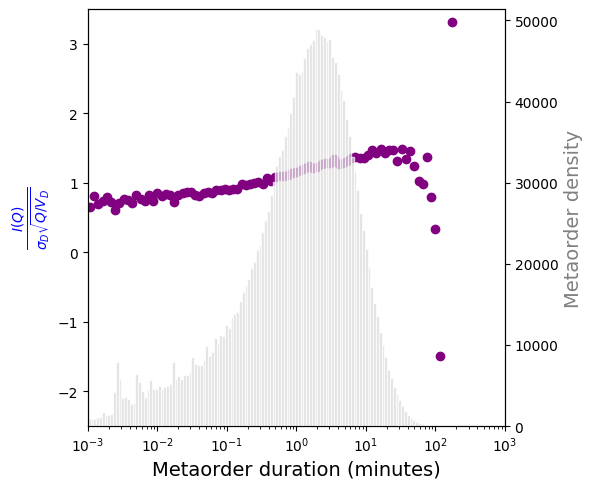

In [55]:
n_intervals = 100

df = GFI_metaorders.with_columns(pl.col('duration (min)').alias('x_meta'),
                            (pl.col('metaorder impact') / (pl.col('20 AD volatility') * np.sqrt((pl.col('volume traded') / pl.col('20 AD volume'))))).fill_nan(None).alias('y_meta'))

bins = np.logspace(-3, 3, n_intervals)
df   = df.with_columns([pl.Series('bin', np.digitize(df['x_meta'].to_numpy(), bins) - 1)])

all_bins = pl.DataFrame({'bin': np.arange(len(bins) - 1)})
binned   = df.group_by('bin').agg(pl.col('y_meta').mean().alias('y_mean')).sort('bin')
binned   = all_bins.join(binned, on = 'bin', how = 'left').sort('bin')

bin_centers = (bins[:-1] + bins[1:]) / 2
binned      = binned.with_columns(x_center = bin_centers)

fig, ax1 = plt.subplots(figsize = (6, 6))

ax1.set_xscale('log')
ax1.set_xlim(1e-3, 1e3)
ax1.set_ylim(-2.5, 3.5)

ax1.scatter(binned['x_center'], binned['y_mean'], color = col, marker = 'o')

ax1.set_xlabel('Metaorder duration (minutes)', fontsize = 14)
ax1.set_ylabel(r'$\frac{I(Q)}{\sigma_{D} \sqrt{Q/V_{D}}}$', fontsize = 14, color = 'blue')
ax1.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase = False))

# Histogram (right axis)
ax2 = ax1.twinx()
bins = np.logspace(-3, 3, 150)
ax2.hist(df['x_meta'], bins = bins, color = 'lightgray', edgecolor = 'white', alpha = 0.7)
ax2.set_ylabel('Metaorder density', fontsize = 14, color = 'gray')

ax1.set_box_aspect(1)
plt.tight_layout()

plt.savefig(f'{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf')
b2.put_file(f'{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf', f'figures_2/time_independence/{exchange}/calibrated/{config}')
b2.get_file(f'figures_2/time_independence/{exchange}/calibrated/{config}/{ticker}_{exchange}_{config}_{flag}_calibrated_time_independence.pdf')

plt.show()